### Import libraries and set project paths

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 100)

PROJECT_ROOT = Path.cwd().parent
INPUT_PATH = PROJECT_ROOT / 'reports' / 'retention' / 'customer_retention_priority.csv'
OUTPUT_DIR = PROJECT_ROOT / 'reports' / 'clv'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT.resolve())
print('Input file:', INPUT_PATH.resolve())
print('Output directory:', OUTPUT_DIR.resolve())

Project root: C:\CHURNIQ
Input file: C:\CHURNIQ\REPORTS\retention\customer_retention_priority.csv
Output directory: C:\CHURNIQ\REPORTS\clv


### Load and validate Notebook 07 results

In [2]:
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f'Required file not found: {INPUT_PATH.resolve()}\n'
        'Run Notebook 07 and confirm it exports reports/retention/customer_retention_priority.csv.'
    )

customers = pd.read_csv(INPUT_PATH)
customers.columns = [str(c).strip().lower() for c in customers.columns]
print('Rows, columns:', customers.shape)
display(customers.head())

def find_column(frame, candidates):
    for candidate in candidates:
        if candidate in frame.columns:
            return candidate
    return None

charge_col = find_column(customers, ['monthly_charges', 'monthlycharges', 'monthly_charge'])
risk_col = find_column(customers, ['predicted_churn_probability', 'churn_probability', 'predicted_churn_prob'])
id_col = find_column(customers, ['customer_id', 'customerid', 'customerid'])

if charge_col is None:
    raise ValueError('Monthly charges column was not found. Expected monthly_charges or MonthlyCharges in Notebook 07 output.')
if risk_col is None:
    raise ValueError('Predicted churn probability column was not found. Check Notebook 07 output.')

customers[charge_col] = pd.to_numeric(customers[charge_col], errors='coerce')
customers[risk_col] = pd.to_numeric(customers[risk_col], errors='coerce').clip(0, 1)
customers = customers.dropna(subset=[charge_col, risk_col]).copy()
customers[charge_col] = customers[charge_col].clip(lower=0)

if id_col is None:
    customers['customer_id'] = [f'customer_{i+1}' for i in range(len(customers))]
    id_col = 'customer_id'

print('Customers available for CLV scenarios:', len(customers))
print('Average monthly charge:', round(customers[charge_col].mean(), 2))
print('Average predicted churn probability:', round(customers[risk_col].mean(), 4))

Rows, columns: (7043, 12)


,customer_id,predicted_churn_probability,actual_churn,tenure_months,monthly_charges,contract_type,internet_service,churn_risk_band,retention_priority,recommended_retention_action,shap_context_file,historical_survival_probability_at_tenure
0,6618-RYATB,0.905174,1,1,79.55,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,shap_feature_importance.csv,0.945961
1,1448-PWKYE,0.905174,1,1,80.00,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,shap_feature_importance.csv,0.945961
2,2514-GINMM,0.905174,1,1,79.50,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,shap_feature_importance.csv,0.945961
3,9019-QVLZD,0.905174,1,1,79.55,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,shap_feature_importance.csv,0.945961
4,9300-RENDD,0.905174,1,1,79.95,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,shap_feature_importance.csv,0.945961


Customers available for CLV scenarios: 7043
Average monthly charge: 64.76
Average predicted churn probability: 0.2658


### Set transparent financial assumptions

In [3]:
# Scenario assumptions — edit as needed
CONTRIBUTION_MARGIN = 0.30      # 30% of monthly revenue treated as contribution
FORECAST_HORIZON_MONTHS = 24   # maximum months included in the scenario
MONTHLY_DISCOUNT_RATE = 0.01   # 1% monthly discount rate

if not 0 <= CONTRIBUTION_MARGIN <= 1:
    raise ValueError('CONTRIBUTION_MARGIN must be between 0 and 1.')
if FORECAST_HORIZON_MONTHS < 1:
    raise ValueError('FORECAST_HORIZON_MONTHS must be at least 1.')
if MONTHLY_DISCOUNT_RATE < 0:
    raise ValueError('MONTHLY_DISCOUNT_RATE cannot be negative.')

print(f'Contribution margin: {CONTRIBUTION_MARGIN:.0%}')
print(f'Forecast horizon: {FORECAST_HORIZON_MONTHS} months')
print(f'Monthly discount rate: {MONTHLY_DISCOUNT_RATE:.2%}')

Contribution margin: 30%
Forecast horizon: 24 months
Monthly discount rate: 1.00%


### Calculate customer-level CLV scenarios

In [4]:

#For each customer, the model calculates monthly contribution as monthly charges × contribution margin. The base scenario uses 1 - predicted_churn_probability as a simple retention factor for each projected month. Since the classifier predicts churn status from a snapshot rather than monthly churn hazard, interpret this as an illustrative scenario—not a statistically validated survival curve.

clv = customers.copy()
clv['monthly_revenue'] = clv[charge_col]
clv['estimated_monthly_contribution'] = clv['monthly_revenue'] * CONTRIBUTION_MARGIN
clv['retention_factor_assumption'] = (1 - clv[risk_col]).clip(0, 1)

month_numbers = np.arange(1, FORECAST_HORIZON_MONTHS + 1, dtype=float)
discount_factors = 1 / ((1 + MONTHLY_DISCOUNT_RATE) ** month_numbers)

def discounted_scenario_clv(monthly_contribution, retention_factor):
    survival_weights = np.power(retention_factor, month_numbers - 1)
    return float(np.sum(monthly_contribution * survival_weights * discount_factors))

clv['estimated_clv_base'] = [
    discounted_scenario_clv(contribution, retention)
    for contribution, retention in zip(clv['estimated_monthly_contribution'], clv['retention_factor_assumption'])
]

# Sensitivity scenarios: lower/higher retention factors, capped to valid probability range.
clv['estimated_clv_conservative'] = [
    discounted_scenario_clv(contribution, max(0, retention - 0.10))
    for contribution, retention in zip(clv['estimated_monthly_contribution'], clv['retention_factor_assumption'])
]
clv['estimated_clv_optimistic'] = [
    discounted_scenario_clv(contribution, min(1, retention + 0.10))
    for contribution, retention in zip(clv['estimated_monthly_contribution'], clv['retention_factor_assumption'])
]

clv['clv_scenario_band'] = pd.cut(
    clv['estimated_clv_base'],
    bins=[-np.inf, clv['estimated_clv_base'].quantile(0.33), clv['estimated_clv_base'].quantile(0.67), np.inf],
    labels=['Lower CLV', 'Middle CLV', 'Higher CLV'],
    include_lowest=True,
    duplicates='drop'
)

display(clv[[id_col, charge_col, risk_col, 'estimated_monthly_contribution', 'estimated_clv_conservative', 'estimated_clv_base', 'estimated_clv_optimistic', 'clv_scenario_band']].head(10))

,customer_id,monthly_charges,predicted_churn_probability,estimated_monthly_contribution,estimated_clv_conservative,estimated_clv_base,estimated_clv_optimistic,clv_scenario_band
0,6618-RYATB,79.55,0.905174,23.865,23.628713,26.077001,29.275949,Lower CLV
1,1448-PWKYE,80.00,0.905174,24.000,23.762376,26.224514,29.441557,Lower CLV
2,2514-GINMM,79.50,0.905174,23.850,23.613861,26.060610,29.257548,Lower CLV
3,9019-QVLZD,79.55,0.905174,23.865,23.628713,26.077001,29.275949,Lower CLV
4,9300-RENDD,79.95,0.905174,23.985,23.747525,26.208123,29.423156,Lower CLV
5,8821-XNHVZ,80.05,0.905174,24.015,23.777228,26.240904,29.459958,Lower CLV
6,7903-CMPEY,80.30,0.905174,24.090,23.851485,26.322856,29.551963,Lower CLV
7,1761-AEZZR,79.55,0.905174,23.865,23.628713,26.077001,29.275949,Lower CLV
8,6086-ESGRL,80.15,0.905174,24.045,23.806931,26.273685,29.496760,Lower CLV
9,5494-HECPR,80.25,0.905174,24.075,23.836634,26.306465,29.533562,Lower CLV


### Summarize CLV and retention-risk segments

In [5]:
# This summary helps identify customers with high estimated contribution value and high churn risk for review. It does not prove that a retention offer will change their behavior.

clv['value_risk_segment'] = np.select(
    [
        (clv['estimated_clv_base'] >= clv['estimated_clv_base'].median()) & (clv[risk_col] >= 0.60),
        (clv['estimated_clv_base'] >= clv['estimated_clv_base'].median()) & (clv[risk_col] < 0.60),
        (clv['estimated_clv_base'] < clv['estimated_clv_base'].median()) & (clv[risk_col] >= 0.60),
    ],
    ['High value / high risk', 'High value / lower risk', 'Lower value / high risk'],
    default='Lower value / lower risk'
)

segment_summary = (
    clv.groupby('value_risk_segment', dropna=False)
    .agg(
        customer_count=(id_col, 'count'),
        average_monthly_revenue=('monthly_revenue', 'mean'),
        average_predicted_churn_probability=(risk_col, 'mean'),
        average_estimated_clv=('estimated_clv_base', 'mean'),
        total_estimated_clv=('estimated_clv_base', 'sum'),
    )
    .reset_index()
    .sort_values('total_estimated_clv', ascending=False)
)
display(segment_summary)

,value_risk_segment,customer_count,average_monthly_revenue,average_predicted_churn_probability,average_estimated_clv,total_estimated_clv
0,High value / lower risk,3522,63.472516,0.087880,202.094326,711776.214617
2,Lower value / lower risk,2688,62.175279,0.357163,53.866971,144794.417454
1,Lower value / high risk,833,78.558523,0.723256,32.454324,27034.451602


### Visualize the scenario results

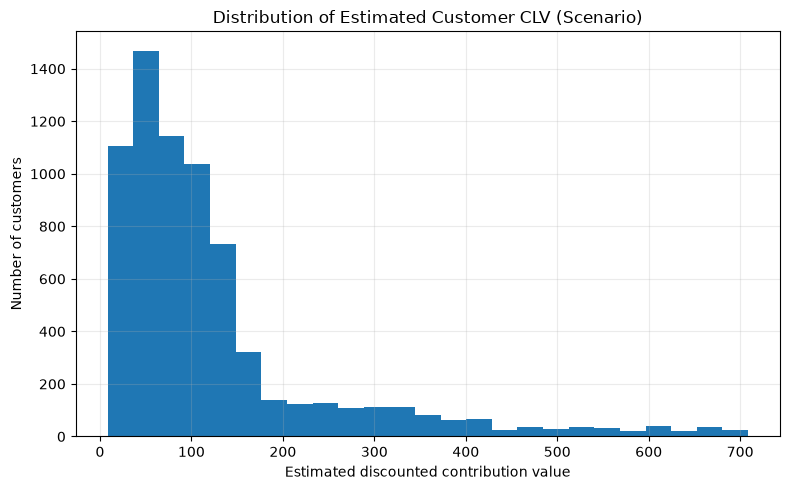

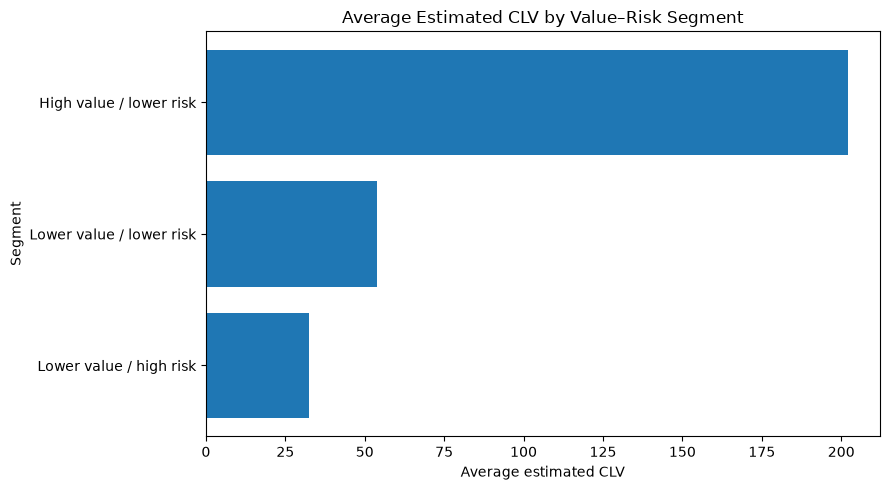

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(clv['estimated_clv_base'].dropna(), bins=25)
plt.title('Distribution of Estimated Customer CLV (Scenario)')
plt.xlabel('Estimated discounted contribution value')
plt.ylabel('Number of customers')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('Distribution of Estimated Customer CLV (Scenario)', dpi=300, bbox_inches="tight")
plt.show()

segment_plot = segment_summary.sort_values('average_estimated_clv', ascending=True)
plt.figure(figsize=(9, 5))
plt.barh(segment_plot['value_risk_segment'], segment_plot['average_estimated_clv'])
plt.title('Average Estimated CLV by Value–Risk Segment')
plt.xlabel('Average estimated CLV')
plt.ylabel('Segment')
plt.tight_layout()
plt.savefig('Average Estimated CLV by Value–Risk Segment', dpi=300, bbox_inches="tight")
plt.show()

### Export results for Notebook 09

In [7]:
# The customer-level output contains all input fields from Notebook 07 plus the CLV assumptions and scenario estimates. Notebook 09 can use estimated_clv_base as an illustrative value input when simulating retention costs and benefits.

customer_output = OUTPUT_DIR / 'customer_clv_scenarios.csv'
segment_output = OUTPUT_DIR / 'clv_segment_summary.csv'
summary_output = OUTPUT_DIR / 'clv_summary.json'

clv.to_csv(customer_output, index=False)
segment_summary.to_csv(segment_output, index=False)

summary = {
    'customers_scored': int(len(clv)),
    'contribution_margin_assumption': CONTRIBUTION_MARGIN,
    'forecast_horizon_months': FORECAST_HORIZON_MONTHS,
    'monthly_discount_rate': MONTHLY_DISCOUNT_RATE,
    'mean_estimated_clv_base': float(clv['estimated_clv_base'].mean()),
    'median_estimated_clv_base': float(clv['estimated_clv_base'].median()),
    'total_estimated_clv_base': float(clv['estimated_clv_base'].sum()),
    'interpretation': 'Assumption-based scenario estimate, not a validated financial forecast or causal retention impact estimate.'
}
summary_output.write_text(json.dumps(summary, indent=2), encoding='utf-8')

print('Saved:', customer_output.resolve())
print('Saved:', segment_output.resolve())
print('Saved:', summary_output.resolve())
display(pd.DataFrame([summary]))

Saved: C:\CHURNIQ\REPORTS\clv\customer_clv_scenarios.csv
Saved: C:\CHURNIQ\REPORTS\clv\clv_segment_summary.csv
Saved: C:\CHURNIQ\REPORTS\clv\clv_summary.json


,customers_scored,contribution_margin_assumption,forecast_horizon_months,monthly_discount_rate,mean_estimated_clv_base,median_estimated_clv_base,total_estimated_clv_base,interpretation
0,7043,0.3,24,0.01,125.458623,86.396279,883605.083674,"Assumption-based scenario estimate, not a vali..."
